# EV charging in Palo Alto

## Section 2: Data analysis and visualization
This part of the notebook goes with Section 2 of our report. We start with almost ten years of charging sessions from Palo Alto, July 2011 to December 2020. We finish with one table saying how much energy each station used in each hour and how long its plugs were occupied. Tasks 1 and 2 both need that table.

The road there: load the data, fix the dates, sort out the time zones, remove the sessions that are lying to us, tidy the station names, build the hourly tables, and finally look at some plots.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 2.1 Loading the data
`User ID` is read as text on purpose. Otherwise pandas guesses the type separately for each chunk of this big file, and the same driver can turn up as both `3421` and `3421.0`. That inflated 21,441 drivers to 27,698, which is a lot of people who don't exist.

In [2]:
df = pd.read_csv(
    "EVChargingStationUsage.csv",
    dtype={"User ID": str, "County": str, "Model Number": str}
)
print(df.head(10))
print(df.shape)

                 Station Name          MAC Address           Org Name  \
0  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
1  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
2  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
3  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
4  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
5  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
6  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
7  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
8  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
9  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   

        Start Date Start Time Zone         End Date End Time Zone  \
0  7/29/2011 20:17             PDT  7/29/2011 23:20           PDT   
1   7/30/2011 0:00             PDT   7/30/2011 0:02       

Each row is one charging session. About a third of `EVSE ID` and `County` is empty, but we don't need those columns for the hourly tables.

Four rows are exact copies of another row, down to the event ID. Nobody charged twice at the same minute at the same plug, so we removed the copies. Otherwise their energy gets counted twice.

In [3]:
print(df.isnull().sum())
print(df.duplicated().sum())

# Remove exact duplicate records so their energy is not counted twice
df = df.drop_duplicates().reset_index(drop=True)
print("Records after removing exact duplicates:", len(df))

Station Name                           0
MAC Address                            0
Org Name                               0
Start Date                             0
Start Time Zone                        0
End Date                               0
End Time Zone                          0
Transaction Date (Pacific Time)      209
Total Duration (hh:mm:ss)              0
Charging Time (hh:mm:ss)               0
Energy (kWh)                           0
GHG Savings (kg)                       0
Gasoline Savings (gallons)             0
Port Type                              9
Port Number                            0
Plug Type                              0
EVSE ID                            78948
Address 1                              0
City                                   0
State/Province                         0
Postal Code                            0
Country                                0
Latitude                               0
Longitude                              0
Currency        

### 2.2 Fixing the dates
Forty `End Date` values from 20 April 2017 look like `42845.81041`. That is how Excel stores a date (days since 1899), so at some point this file met Excel and came back changed. Converted properly, they agree with the recorded duration to within about a minute, so we keep them.

In [4]:
# Some End Date values are stored as Excel serial numbers (days since 1899-12-30)
excel_end = pd.to_numeric(df["End Date"], errors="coerce")
is_excel = excel_end.notna()
print("End Date values in Excel format:", is_excel.sum())

date_format = "%m/%d/%Y %H:%M"
df["Start Date"] = pd.to_datetime(df["Start Date"], format=date_format, errors="coerce")
df["End Date"] = pd.to_datetime(df["End Date"], format=date_format, errors="coerce")

# Convert the Excel values, rounding to the minute like the other timestamps
df.loc[is_excel, "End Date"] = (
    pd.Timestamp("1899-12-30") + pd.to_timedelta(excel_end[is_excel], unit="D")
).dt.round("min")

total_td = pd.to_timedelta(df['Total Duration (hh:mm:ss)'], errors='coerce')
chg_td = pd.to_timedelta(df['Charging Time (hh:mm:ss)'], errors='coerce')

End Date values in Excel format: 40


First sanity check. 43 sessions seem to end before they start, or at the exact same minute. We look into those below. The energy column, at least, behaves: nothing zero or negative.

In [5]:
invalid_dates = ( df["Start Date"].isna()| df["End Date"].isna()| (df["End Date"] <= df["Start Date"]))
print("Invalid timestamp records:", invalid_dates.sum())
display(df.loc[invalid_dates,["Start Date","End Date","Total Duration (hh:mm:ss)","Charging Time (hh:mm:ss)","Energy (kWh)"]].head(20))
print("Negative energy:", (df["Energy (kWh)"] < 0).sum())
print("Zero energy:", (df["Energy (kWh)"] == 0).sum())
print(df["Total Duration (hh:mm:ss)"].value_counts().head())

Invalid timestamp records: 43


,Start Date,End Date,Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh)
390,2011-10-10 15:23:00,2011-10-10 15:23:00,4:34:38,2:37:06,9.155255
15461,2013-10-03 12:21:00,2013-10-03 12:21:00,0:38:10,0:38:04,2.286150
15463,2013-10-03 12:31:00,2013-10-03 12:31:00,2:48:15,2:45:16,3.526191
15464,2013-10-03 12:31:00,2013-10-03 12:31:00,0:55:05,0:54:49,2.805981
15465,2013-10-03 12:41:00,2013-10-03 12:41:00,1:11:00,1:09:09,2.085362
15466,2013-10-03 12:51:00,2013-10-03 12:51:00,0:25:55,0:25:39,0.959668
15469,2013-10-03 13:12:00,2013-10-03 13:12:00,2:32:34,2:21:55,8.072627
15470,2013-10-03 13:32:00,2013-10-03 13:32:00,5:11:19,2:01:04,6.019720
15472,2013-10-03 13:42:00,2013-10-03 13:42:00,1:01:34,1:01:19,3.674747
15474,2013-10-03 13:52:00,2013-10-03 13:52:00,8:46:58,3:59:31,12.199721


Negative energy: 0
Zero energy: 0
Total Duration (hh:mm:ss)
0:01:17    36
1:29:33    36
1:20:51    36
1:05:34    36
0:01:11    35
Name: count, dtype: int64


### 2.3 Time zones
Most sessions are labelled PDT or PST, but 120 start in one zone and end in another. Most of those sit around clock changes, and a few claim to be in UTC. Simply doing End minus Start would be wrong for all of them.

In [6]:
# Count the start/end time-zone combinations
print(
    df.groupby(
        ["Start Time Zone", "End Time Zone"],
        dropna=False
    ).size().reset_index(name="Records")
)

  Start Time Zone End Time Zone  Records
0             PDT           PDT   166731
1             PDT           PST       30
2             PDT           UTC        1
3             PST           PDT       58
4             PST           PST    92560
5             UTC           PDT        1
6             UTC           PST       30


So we convert everything to UTC, which has no daylight saving, and measure durations there. Then we also keep Palo Alto local time, because that's the clock drivers actually live by. If we stayed in UTC, 28.5% of sessions would land on the wrong weekday and a morning commute would look like a late-night habit.

In [7]:
zone_map = {
    "PST": "Etc/GMT+8",
    "PDT": "Etc/GMT+7",
    "UTC": "UTC"
}

# Create new UTC columns; do not overwrite the original timestamps
df["Start_UTC"] = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns, UTC]")
df["End_UTC"] = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns, UTC]")

# Convert each start timestamp according to its own label
for label, timezone in zone_map.items():
    mask = ( df["Start Time Zone"].eq(label) & df["Start Date"].notna())
    df.loc[mask, "Start_UTC"] = ( df.loc[mask, "Start Date"] .dt.tz_localize(timezone).dt.tz_convert("UTC"))

# Convert each end timestamp according to its own label
for label, timezone in zone_map.items():
    mask = ( df["End Time Zone"].eq(label) & df["End Date"].notna())
    df.loc[mask, "End_UTC"] = (df.loc[mask, "End Date"].dt.tz_localize(timezone).dt.tz_convert("UTC"))

# Calculate elapsed time using the converted timestamps
df["Elapsed_UTC_Minutes"] = (df["End_UTC"] - df["Start_UTC"]).dt.total_seconds() / 60

# Local Palo Alto time, used for hours of the day, weekdays and day boundaries
local_tz = "America/Los_Angeles"
df["Start_Local"] = df["Start_UTC"].dt.tz_convert(local_tz)
df["End_Local"] = df["End_UTC"].dt.tz_convert(local_tz)

# Check the results
display(
    df[["Start Date", "Start Time Zone", "Start_UTC","End Date", "End Time Zone", "End_UTC",
            "Elapsed_UTC_Minutes","Total Duration (hh:mm:ss)"]].head(10))

,Start Date,Start Time Zone,Start_UTC,End Date,End Time Zone,End_UTC,Elapsed_UTC_Minutes,Total Duration (hh:mm:ss)
0,2011-07-29 20:17:00,PDT,2011-07-30 03:17:00+00:00,2011-07-29 23:20:00,PDT,2011-07-30 06:20:00+00:00,183.0,3:03:32
1,2011-07-30 00:00:00,PDT,2011-07-30 07:00:00+00:00,2011-07-30 00:02:00,PDT,2011-07-30 07:02:00+00:00,2.0,0:02:06
2,2011-07-30 08:16:00,PDT,2011-07-30 15:16:00+00:00,2011-07-30 12:34:00,PDT,2011-07-30 19:34:00+00:00,258.0,4:17:32
3,2011-07-30 14:51:00,PDT,2011-07-30 21:51:00+00:00,2011-07-30 16:55:00,PDT,2011-07-30 23:55:00+00:00,124.0,2:03:24
4,2011-07-30 18:51:00,PDT,2011-07-31 01:51:00+00:00,2011-07-30 20:03:00,PDT,2011-07-31 03:03:00+00:00,72.0,1:11:24
5,2011-07-30 21:38:00,PDT,2011-07-31 04:38:00+00:00,2011-07-31 01:30:00,PDT,2011-07-31 08:30:00+00:00,232.0,3:52:13
6,2011-07-31 04:33:00,PDT,2011-07-31 11:33:00+00:00,2011-07-31 10:40:00,PDT,2011-07-31 17:40:00+00:00,367.0,6:06:19
7,2011-07-31 12:25:00,PDT,2011-07-31 19:25:00+00:00,2011-07-31 13:35:00,PDT,2011-07-31 20:35:00+00:00,70.0,1:09:54
8,2011-07-31 17:41:00,PDT,2011-08-01 00:41:00+00:00,2011-07-31 22:31:00,PDT,2011-08-01 05:31:00+00:00,290.0,4:49:46
9,2011-08-01 19:11:00,PDT,2011-08-02 02:11:00+00:00,2011-08-01 22:34:00,PDT,2011-08-02 05:34:00+00:00,203.0,3:23:34


### 2.4 Can we trust the durations?
The data gives us session length twice: once in the timestamps and once in `Total Duration`. So we can check one against the other. They disagree by more than two minutes for 339 sessions. The best one is at MPL #6, where the timestamps say someone stayed plugged in for 82 days. Great parking spot.

In [8]:
# Convert recorded duration to minutes
recorded_minutes = total_td.dt.total_seconds() / 60

# Compare elapsed time with recorded duration
df["UTC_Duration_Difference_Minutes"] = (
    df["Elapsed_UTC_Minutes"] - recorded_minutes
).abs()

# Summarize the differences
print("Total records:", len(df))
print(
    "Records with difference over 2 minutes:",
    (df["UTC_Duration_Difference_Minutes"] > 2).sum()
)
print(
    "Records with negative UTC duration:",
    (df["Elapsed_UTC_Minutes"] <= 0).sum()
)

display(
    df.sort_values(
        "UTC_Duration_Difference_Minutes",
        ascending=False
    )[
        [
            "Start Date",
            "Start Time Zone",
            "Start_UTC",
            "End Date",
            "End Time Zone",
            "End_UTC",
            "Total Duration (hh:mm:ss)",
            "Elapsed_UTC_Minutes",
            "UTC_Duration_Difference_Minutes"
        ]
    ].head(15)
)

Total records: 259411
Records with difference over 2 minutes: 339
Records with negative UTC duration: 12


,Start Date,Start Time Zone,Start_UTC,End Date,End Time Zone,End_UTC,Total Duration (hh:mm:ss),Elapsed_UTC_Minutes,UTC_Duration_Difference_Minutes
38665,2015-06-18 13:01:00,PDT,2015-06-18 20:01:00+00:00,2015-09-08 20:24:00,PDT,2015-09-09 03:24:00+00:00,1:25:09,118523.0,118437.850000
38663,2015-06-18 12:10:00,PDT,2015-06-18 19:10:00+00:00,2015-09-08 20:21:00,PDT,2015-09-09 03:21:00+00:00,2:18:01,118571.0,118432.983333
38605,2015-06-17 13:04:00,PDT,2015-06-17 20:04:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,0:30:13,102053.0,102022.783333
38608,2015-06-17 14:24:00,PDT,2015-06-17 21:24:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,1:25:51,101973.0,101887.150000
38643,2015-06-18 06:28:00,PDT,2015-06-18 13:28:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,1:25:22,101009.0,100923.633333
38672,2015-06-18 13:55:00,PDT,2015-06-18 20:55:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,0:05:10,100562.0,100556.833333
38673,2015-06-18 14:13:00,PDT,2015-06-18 21:13:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,0:15:18,100544.0,100528.700000
39194,2015-06-30 13:14:00,PDT,2015-06-30 20:14:00+00:00,2015-08-27 09:57:00,PDT,2015-08-27 16:57:00+00:00,0:20:16,83323.0,83302.733333
2389,2012-03-27 14:40:00,PDT,2012-03-27 21:40:00+00:00,2012-05-09 12:43:00,PDT,2012-05-09 19:43:00+00:00,22:59:59,61803.0,60423.016667
16244,2013-10-30 17:28:00,PDT,2013-10-31 00:28:00+00:00,2013-12-06 09:45:00,PST,2013-12-06 17:45:00+00:00,22:59:59,52877.0,51497.016667


And then there are the 12 sessions with zero or negative length, 11 of them at Bryant #2. Time travel is not a service this company offers.

In [9]:
# Find records with zero or negative UTC duration
nonpositive_utc = df[
    df["Elapsed_UTC_Minutes"] <= 0
].copy()

# Select only the important columns
columns_to_show = [
    "Station Name",
    "Start Date",
    "Start Time Zone",
    "End Date",
    "End Time Zone",
    "Total Duration (hh:mm:ss)",
    "Elapsed_UTC_Minutes"
]

# Display as a readable table
display(
    nonpositive_utc[columns_to_show]
    .reset_index(drop=True)
)

print("Number of records to investigate:", len(nonpositive_utc))

,Station Name,Start Date,Start Time Zone,End Date,End Time Zone,Total Duration (hh:mm:ss),Elapsed_UTC_Minutes
0,PALO ALTO CA / BRYANT #2,2011-10-10 15:23:00,PDT,2011-10-10 15:23:00,PDT,4:34:38,0.0
1,PALO ALTO CA / BRYANT #2,2013-10-03 12:21:00,PDT,2013-10-03 12:21:00,PDT,0:38:10,0.0
2,PALO ALTO CA / BRYANT #2,2013-10-03 12:31:00,PDT,2013-10-03 12:31:00,PDT,2:48:15,0.0
3,PALO ALTO CA / BRYANT #2,2013-10-03 12:31:00,PDT,2013-10-03 12:31:00,PDT,0:55:05,0.0
4,PALO ALTO CA / BRYANT #2,2013-10-03 12:41:00,PDT,2013-10-03 12:41:00,PDT,1:11:00,0.0
5,PALO ALTO CA / BRYANT #2,2013-10-03 12:51:00,PDT,2013-10-03 12:51:00,PDT,0:25:55,0.0
6,PALO ALTO CA / BRYANT #2,2013-10-03 13:12:00,PDT,2013-10-03 13:12:00,PDT,2:32:34,0.0
7,PALO ALTO CA / BRYANT #2,2013-10-03 13:32:00,PDT,2013-10-03 13:32:00,PDT,5:11:19,0.0
8,PALO ALTO CA / BRYANT #2,2013-10-03 13:42:00,PDT,2013-10-03 13:42:00,PDT,1:01:34,0.0
9,PALO ALTO CA / BRYANT #2,2013-10-03 13:52:00,PDT,2013-10-03 13:52:00,PDT,8:46:58,0.0


Number of records to investigate: 12


We keep a session only if its timestamps make sense and match the recorded duration. That costs us 339 of 259,411 sessions (0.13%), which we can live with.

We also store durations in minutes for later. In 6 sessions the charging time is longer than the time plugged in, by about a minute at most. That looks like clock rounding, so we cap charging time at the plugged-in time.

In [10]:
# Step 1: Ensure energy is numeric
df["Energy (kWh)"] = pd.to_numeric(
    df["Energy (kWh)"], errors="coerce"
)

# Step 2: Identify records suitable for initial time-based analysis
time_quality_mask = (
    df["Start_UTC"].notna()
    & df["End_UTC"].notna()
    & (df["Elapsed_UTC_Minutes"] > 0)
    & (df["UTC_Duration_Difference_Minutes"] <= 2)
    & df["Station Name"].notna()
    & df["Energy (kWh)"].notna()
)

# Step 3: Create a separate analysis dataset
df_time_clean = df.loc[time_quality_mask].copy()

# Step 4: Keep the records requiring review separately
df_time_review = df.loc[~time_quality_mask].copy()

# Step 5: Store durations in minutes, used later to build the hourly data
# Charging cannot exceed the time plugged in; the few small excesses are clock rounding
charging_time = chg_td.loc[df_time_clean.index]
total_time = total_td.loc[df_time_clean.index]
print("Charging time above total duration:", (charging_time > total_time).sum())

df_time_clean["Charging_Minutes"] = charging_time.clip(upper=total_time).dt.total_seconds() / 60
df_time_clean["Total_Minutes"] = total_time.dt.total_seconds() / 60

# Step 6: Check the results
print("Original records:", len(df))
print("Records for initial time-based analysis:", len(df_time_clean))
print("Records requiring review:", len(df_time_review))

print("\nReview reasons:")
print("Missing UTC timestamps:",
      (df["Start_UTC"].isna() | df["End_UTC"].isna()).sum())
print("Zero or negative elapsed duration:",
      (df["Elapsed_UTC_Minutes"] <= 0).sum())
print("Duration difference over 2 minutes:",
      (df["UTC_Duration_Difference_Minutes"] > 2).sum())

Charging time above total duration: 6
Original records: 259411
Records for initial time-based analysis: 259072
Records requiring review: 339

Review reasons:
Missing UTC timestamps: 0
Zero or negative elapsed duration: 12
Duration difference over 2 minutes: 339


### 2.5 Station names
There are 47 labels, and something looks off at the bottom of the list. Thirteen Sherman stations only appear in December 2020 with 1 to 8 sessions each: they had barely opened when the data ends. There's also a suspicious Bryant.

In [11]:
# Check how many records belong to each station name
station_counts = (
    df_time_clean["Station Name"]
    .value_counts()
    .rename_axis("Station Name")
    .reset_index(name="Session_Count")
)

print("Number of station-name labels:", len(station_counts))

display(station_counts.head(20))

# Check the date range for each station label
station_summary = (
    df_time_clean.groupby("Station Name")
    .agg(
        Sessions=("Energy (kWh)", "size"),
        First_Session=("Start_UTC", "min"),
        Last_Session=("Start_UTC", "max")
    )
    .sort_values("Sessions")
)

display(station_summary.head(15))

Number of station-name labels: 47


,Station Name,Session_Count
0,PALO ALTO CA / HAMILTON #2,23694
1,PALO ALTO CA / HAMILTON #1,14848
2,PALO ALTO CA / WEBSTER #1,14418
3,PALO ALTO CA / BRYANT #2,14305
4,PALO ALTO CA / HIGH #4,13858
5,PALO ALTO CA / BRYANT #1,13398
6,PALO ALTO CA / WEBSTER #2,12662
7,PALO ALTO CA / CAMBRIDGE #1,11161
8,PALO ALTO CA / HIGH #1,10753
9,PALO ALTO CA / WEBSTER #3,10479


,Sessions,First_Session,Last_Session
Station Name,,,
PALO ALTO CA / SHERMAN 11,1,2020-12-29 17:01:00+00:00,2020-12-29 17:01:00+00:00
PALO ALTO CA / SHERMAN 15,1,2020-12-26 21:50:00+00:00,2020-12-26 21:50:00+00:00
PALO ALTO CA / SHERMAN 17,1,2020-12-29 17:03:00+00:00,2020-12-29 17:03:00+00:00
PALO ALTO CA / SHERMAN 5,1,2020-12-26 00:44:00+00:00,2020-12-26 00:44:00+00:00
PALO ALTO CA / SHERMAN 9,1,2020-12-13 20:44:00+00:00,2020-12-13 20:44:00+00:00
PALO ALTO CA / SHERMAN 8,2,2020-12-13 22:35:00+00:00,2020-12-19 04:19:00+00:00
PALO ALTO CA / SHERMAN 14,2,2020-12-18 19:38:00+00:00,2020-12-27 22:34:00+00:00
PALO ALTO CA / SHERMAN 6,3,2020-12-09 22:46:00+00:00,2020-12-31 19:04:00+00:00
PALO ALTO CA / SHERMAN 4,4,2020-12-14 23:10:00+00:00,2020-12-27 19:37:00+00:00


`BRYANT #1` and `BRYANT # 1` differ by one space. Same address (445 Bryant St), and one stops on 30 August 2020 just before the other starts on 6 September. It's one station with a new name tag, so we merge them and end up with 46 stations.

In [12]:
# Create a normalized label for checking only
station_check = df_time_clean[["Station Name"]].drop_duplicates().copy()

station_check["Normalized_Name"] = (
    station_check["Station Name"]
    .str.upper()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*#\s*", " #", regex=True)
)

# Find normalized names that correspond to multiple original labels
name_variations = (
    station_check.groupby("Normalized_Name")["Station Name"]
    .agg(list)
    .reset_index(name="Original_Names")
)

name_variations["Number_of_Variations"] = (
    name_variations["Original_Names"].str.len()
)

name_variations = name_variations[
    name_variations["Number_of_Variations"] > 1
]

display(name_variations)

,Normalized_Name,Original_Names,Number_of_Variations
0,PALO ALTO CA / BRYANT #1,"[PALO ALTO CA / BRYANT #1, PALO ALTO CA / BRYA...",2


In [13]:
print(
    df_time_clean[
        df_time_clean["Station Name"].str.contains(
            "BRYANT", case=False, na=False
        )
    ]["Station Name"].value_counts()
)

Station Name
PALO ALTO CA / BRYANT #2     14305
PALO ALTO CA / BRYANT #1     13398
PALO ALTO CA / BRYANT #6      5856
PALO ALTO CA / BRYANT #5      5329
PALO ALTO CA / BRYANT #3      4466
PALO ALTO CA / BRYANT #4      3596
PALO ALTO CA / BRYANT # 1       13
Name: count, dtype: int64


In [14]:
# Correct the confirmed Bryant #1 naming variation
df_time_clean["Station Name"] = (
    df_time_clean["Station Name"]
    .replace({
        "PALO ALTO CA / BRYANT # 1":
        "PALO ALTO CA / BRYANT #1"
    })
)

# Verify the result
print(
    df_time_clean[
        df_time_clean["Station Name"].str.contains(
            "BRYANT", case=False, na=False
        )
    ]["Station Name"].value_counts()
)

Station Name
PALO ALTO CA / BRYANT #2    14305
PALO ALTO CA / BRYANT #1    13411
PALO ALTO CA / BRYANT #6     5856
PALO ALTO CA / BRYANT #5     5329
PALO ALTO CA / BRYANT #3     4466
PALO ALTO CA / BRYANT #4     3596
Name: count, dtype: int64


### 2.6 From sessions to hours
Our first idea was to put all of a session's energy in the hour it started. Bad idea: 89.1% of sessions keep charging past that hour, so 76.4% of the energy ended up in the wrong place.

Instead, each session is split across every hour it touches. Energy follows `Charging_Minutes`, and occupation follows `Total_Minutes`. The gap between the two is hoarding: the car is full, but it's still sitting on the plug.

Our assumption is constant power from plug-in until charging ends. Real charging slows down near the end, so this is a simplification. The check at the end confirms that the split doesn't create or lose any energy.

In [15]:
# Split each session across the clock hours it covers.
# Assumption: the car charges continuously at constant power from plug-in,
# so energy is shared in proportion to the charging minutes in each hour.
def split_sessions_by_hour(sessions):
    start = sessions["Start_UTC"]
    charge_end = start + pd.to_timedelta(sessions["Charging_Minutes"], unit="min")
    plug_end = start + pd.to_timedelta(sessions["Total_Minutes"], unit="min")
    first_hour = start.dt.floor("h")

    # Repeat each session once for every clock hour it touches
    hours_covered = np.ceil((plug_end - first_hour) / pd.Timedelta(hours=1)).astype(int)
    position = np.repeat(np.arange(len(sessions)), hours_covered)
    offset = pd.Series(position).groupby(position).cumcount()

    split = sessions.iloc[position][["Station Name", "User ID"]].reset_index(drop=True)
    start = start.iloc[position].reset_index(drop=True)
    charge_end = charge_end.iloc[position].reset_index(drop=True)
    plug_end = plug_end.iloc[position].reset_index(drop=True)
    hour = first_hour.iloc[position].reset_index(drop=True) + pd.to_timedelta(offset, unit="h")
    next_hour = hour + pd.Timedelta(hours=1)

    # Minutes of the session that fall inside each clock hour
    begin = start.where(start > hour, hour)
    charge_minutes = ((charge_end.where(charge_end < next_hour, next_hour) - begin)
                      .dt.total_seconds() / 60).clip(lower=0)
    plug_minutes = ((plug_end.where(plug_end < next_hour, next_hour) - begin)
                    .dt.total_seconds() / 60).clip(lower=0)

    energy_per_minute = sessions["Energy (kWh)"].to_numpy() / sessions["Charging_Minutes"].to_numpy()
    split["Hour"] = hour
    split["Energy (kWh)"] = energy_per_minute[position] * charge_minutes
    split["Occupied_Minutes"] = plug_minutes
    return split

session_hours = split_sessions_by_hour(df_time_clean)

# Total energy and occupation for each station and hour
hourly_energy = (
    session_hours
    .groupby(["Station Name", "Hour"])[["Energy (kWh)", "Occupied_Minutes"]]
    .sum()
    .reset_index()
    .sort_values(["Station Name", "Hour"])
)

# The split must not create or lose energy
print("Energy in sessions (kWh):", round(df_time_clean["Energy (kWh)"].sum(), 2))
print("Energy after splitting (kWh):", round(hourly_energy["Energy (kWh)"].sum(), 2))

# Display overall results
print("Hourly observations:", len(hourly_energy))
print("Number of stations:", hourly_energy["Station Name"].nunique())

# Display the first 50 hourly records
display(hourly_energy.head(50))

# Display a summary for ALL stations
station_summary = (
    hourly_energy
    .groupby("Station Name")
    .agg(
        Hourly_Observations=("Hour", "count"),
        Total_Energy_kWh=("Energy (kWh)", "sum"),
        First_Hour=("Hour", "min"),
        Last_Hour=("Hour", "max")
    )
    .reset_index()
    .sort_values("Total_Energy_kWh", ascending=False)
)

print("\nSummary for all stations:")
display(station_summary)

Energy in sessions (kWh): 2213337.13
Energy after splitting (kWh): 2213337.13
Hourly observations: 654347
Number of stations: 46


,Station Name,Hour,Energy (kWh),Occupied_Minutes
0,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00+00:00,0.668822,11.000000
1,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00+00:00,0.961686,15.933333
2,PALO ALTO CA / BRYANT #1,2011-10-14 01:00:00+00:00,0.683024,11.000000
3,PALO ALTO CA / BRYANT #1,2011-10-14 02:00:00+00:00,3.725587,60.000000
4,PALO ALTO CA / BRYANT #1,2011-10-14 03:00:00+00:00,2.222933,35.950000
5,PALO ALTO CA / BRYANT #1,2011-10-14 21:00:00+00:00,0.859986,14.000000
6,PALO ALTO CA / BRYANT #1,2011-10-14 22:00:00+00:00,3.685652,60.000000
7,PALO ALTO CA / BRYANT #1,2011-10-14 23:00:00+00:00,1.713828,27.983333
8,PALO ALTO CA / BRYANT #1,2011-10-15 19:00:00+00:00,1.545526,32.000000
9,PALO ALTO CA / BRYANT #1,2011-10-15 20:00:00+00:00,2.897861,60.000000



Summary for all stations:


,Station Name,Hourly_Observations,Total_Energy_kWh,First_Hour,Last_Hour
12,PALO ALTO CA / HAMILTON #2,53532,191388.341093,2011-08-02 19:00:00+00:00,2020-11-04 14:00:00+00:00
43,PALO ALTO CA / WEBSTER #1,30591,138915.090993,2015-07-29 20:00:00+00:00,2021-01-01 05:00:00+00:00
44,PALO ALTO CA / WEBSTER #2,27600,125692.638719,2015-07-29 23:00:00+00:00,2020-12-31 04:00:00+00:00
11,PALO ALTO CA / HAMILTON #1,44874,113476.602750,2011-07-30 03:00:00+00:00,2020-11-03 22:00:00+00:00
16,PALO ALTO CA / HIGH #4,36208,111531.307913,2011-09-03 03:00:00+00:00,2020-12-07 01:00:00+00:00
1,PALO ALTO CA / BRYANT #2,40177,106725.652087,2011-10-11 02:00:00+00:00,2020-07-02 00:00:00+00:00
0,PALO ALTO CA / BRYANT #1,37877,102157.267243,2011-10-13 19:00:00+00:00,2020-12-25 03:00:00+00:00
45,PALO ALTO CA / WEBSTER #3,22748,98526.874563,2016-01-14 21:00:00+00:00,2020-12-31 23:00:00+00:00
13,PALO ALTO CA / HIGH #1,21581,98375.593769,2015-07-29 22:00:00+00:00,2020-12-31 22:00:00+00:00
39,PALO ALTO CA / TED THOMPSON #1,22181,91167.814604,2016-01-14 18:00:00+00:00,2020-10-11 17:00:00+00:00


That table only has hours when something happened, and a forecasting model needs the quiet hours too. So we build every station-hour from each station's first to last use: 1,533,155 rows, of which 864,143 are simply zero.

Not every zero means nobody wanted to charge, though. A busy station that goes silent for a week is probably broken. We mark a gap as an outage (empty, not zero) if it lasts at least 7 days at a station averaging at least 1 session a day. That gives 14,665 hours, or 0.96% of the table.

The exception is COVID. Gaps starting from 13 March 2020 stay as real zeros, because stations went quiet all over the city at once. People stopped driving, and the chargers didn't all break on the same day. A real outage after that date would be counted as zero demand, and we can't tell the two apart.

In [16]:
# Build a complete table with one row for every station and hour
OUTAGE_HOURS = 7 * 24            # gap with no use that counts as a possible outage
MIN_SESSIONS_PER_DAY = 1         # below this, long gaps can happen by chance
COVID_START = pd.Timestamp("2020-03-13", tz=local_tz)  # later gaps reflect low demand

station_activity = df_time_clean.groupby("Station Name")["Start_UTC"].agg(["size", "min", "max"])
days_observed = (station_activity["max"] - station_activity["min"]).dt.total_seconds() / 86400
sessions_per_day = station_activity["size"] / days_observed

panels = []
for station, station_hours in hourly_energy.groupby("Station Name"):
    panel = station_hours.set_index("Hour")[["Energy (kWh)", "Occupied_Minutes"]]
    all_hours = pd.date_range(panel.index.min(), panel.index.max(), freq="h", name="Hour")
    panel = panel.reindex(all_hours, fill_value=0.0)

    # Measure each run of consecutive unused hours
    used = panel["Occupied_Minutes"] > 0
    gap_id = used.cumsum()
    gap_length = (~used).groupby(gap_id).transform("sum")
    gap_start = panel.index.to_series().where(~used).groupby(gap_id).transform("min")

    # Long gaps at normally active stations, before COVID, are treated as outages
    outage = (
        ~used
        & (gap_length >= OUTAGE_HOURS)
        & (gap_start < COVID_START)
        & (sessions_per_day[station] >= MIN_SESSIONS_PER_DAY)
    )

    panel.loc[outage, ["Energy (kWh)", "Occupied_Minutes"]] = np.nan
    panel["Available"] = ~outage
    panel["Station Name"] = station
    panels.append(panel.reset_index())

hourly_panel = pd.concat(panels, ignore_index=True)[
    ["Station Name", "Hour", "Energy (kWh)", "Occupied_Minutes", "Available"]
]

print("Station-hours:", len(hourly_panel))
print("Hours with no use, station available:", (hourly_panel["Occupied_Minutes"] == 0).sum())
print("Hours marked as outage:", (~hourly_panel["Available"]).sum())
print("Energy in the complete table (kWh):", round(hourly_panel["Energy (kWh)"].sum(), 2))
display(hourly_panel.head(10))


Station-hours: 1533155
Hours with no use, station available: 864143
Hours marked as outage: 14665
Energy in the complete table (kWh): 2213337.13


,Station Name,Hour,Energy (kWh),Occupied_Minutes,Available
0,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00+00:00,0.668822,11.000000,True
1,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00+00:00,0.961686,15.933333,True
2,PALO ALTO CA / BRYANT #1,2011-10-13 21:00:00+00:00,0.000000,0.000000,True
3,PALO ALTO CA / BRYANT #1,2011-10-13 22:00:00+00:00,0.000000,0.000000,True
4,PALO ALTO CA / BRYANT #1,2011-10-13 23:00:00+00:00,0.000000,0.000000,True
5,PALO ALTO CA / BRYANT #1,2011-10-14 00:00:00+00:00,0.000000,0.000000,True
6,PALO ALTO CA / BRYANT #1,2011-10-14 01:00:00+00:00,0.683024,11.000000,True
7,PALO ALTO CA / BRYANT #1,2011-10-14 02:00:00+00:00,3.725587,60.000000,True
8,PALO ALTO CA / BRYANT #1,2011-10-14 03:00:00+00:00,2.222933,35.950000,True
9,PALO ALTO CA / BRYANT #1,2011-10-14 04:00:00+00:00,0.000000,0.000000,True


### 2.7 So what does demand look like?
From now on, hours are in local time. Energy use peaks at noon (174,454 kWh in total) and hits rock bottom at 4 am (9,031 kWh). There's also a small comeback at 6 pm, with 134,685 kWh against 128,629 at 5 pm. These are totals over all the years.

Energy and activity by hour of day:


,Hour_Of_Day,Total_Energy_kWh,Active_Station_Hours
0,0,26919.948847,9695
1,1,19846.816794,8254
2,2,14231.932103,7659
3,3,10735.266998,7521
4,4,9030.749936,7957
5,5,14133.659639,10990
6,6,34922.205068,17011
7,7,64335.126997,23451
8,8,103264.722606,30996
9,9,141095.061948,36849


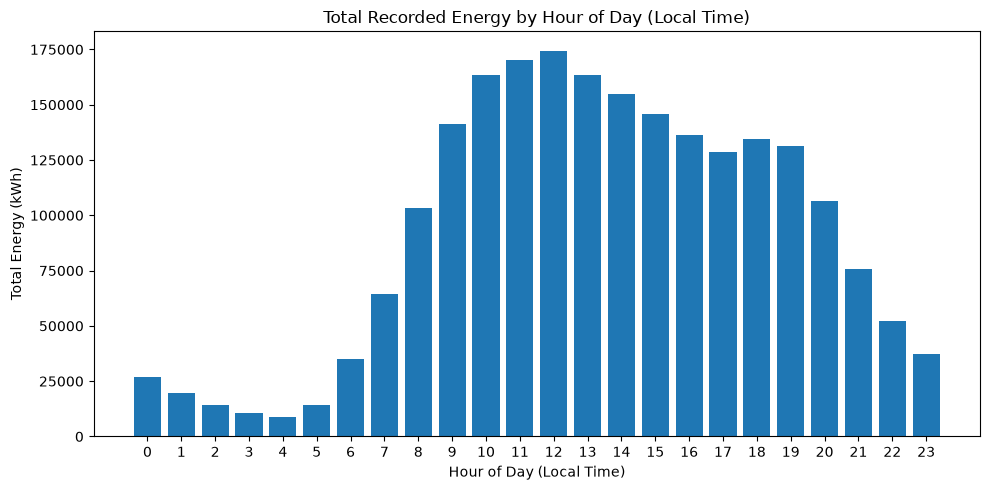

In [17]:
# Extract hour of day in local Palo Alto time
hourly_energy["Hour_Of_Day"] = hourly_energy["Hour"].dt.tz_convert(local_tz).dt.hour

# Calculate total energy and number of active station-hours for each hour
demand_by_hour = (
    hourly_energy.groupby("Hour_Of_Day")
    .agg(
        Total_Energy_kWh=("Energy (kWh)", "sum"),
        Active_Station_Hours=("Station Name", "count")
    )
    .reset_index()
)

print("Energy and activity by hour of day:")
display(demand_by_hour)

# Plot total energy by hour of day
plt.figure(figsize=(10, 5))
plt.bar(
    demand_by_hour["Hour_Of_Day"],
    demand_by_hour["Total_Energy_kWh"]
)
plt.title("Total Recorded Energy by Hour of Day (Local Time)")
plt.xlabel("Hour of Day (Local Time)")
plt.ylabel("Total Energy (kWh)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Which stations do the heavy lifting? Hamilton #2 is the clear winner with 191,388 kWh, about 8.6% of everything in the dataset. Keep in mind that older stations had more years to pile up energy, so this isn't a fair race.

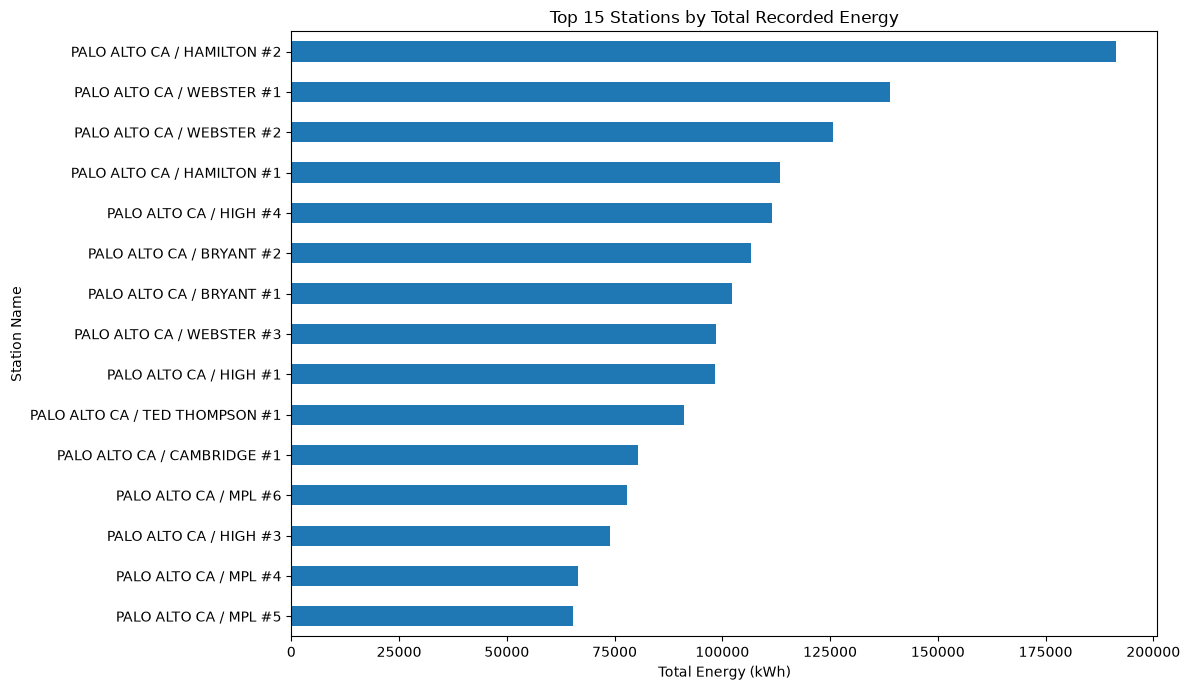

In [18]:
# Calculate total energy for each station
station_energy = (hourly_energy.groupby("Station Name")["Energy (kWh)"].sum().sort_values(ascending=False))

# Select the top 15 stations
top_15 = station_energy.head(15).sort_values()

# Plot with station names
plt.figure(figsize=(12, 7))
top_15.plot(kind="barh")

plt.title("Top 15 Stations by Total Recorded Energy")
plt.xlabel("Total Energy (kWh)")
plt.ylabel("Station Name")
plt.tight_layout()
plt.show()

The same hourly view for the top five stations. Look at the shapes more than the heights, since the heights are totals and depend on how long each station has existed.

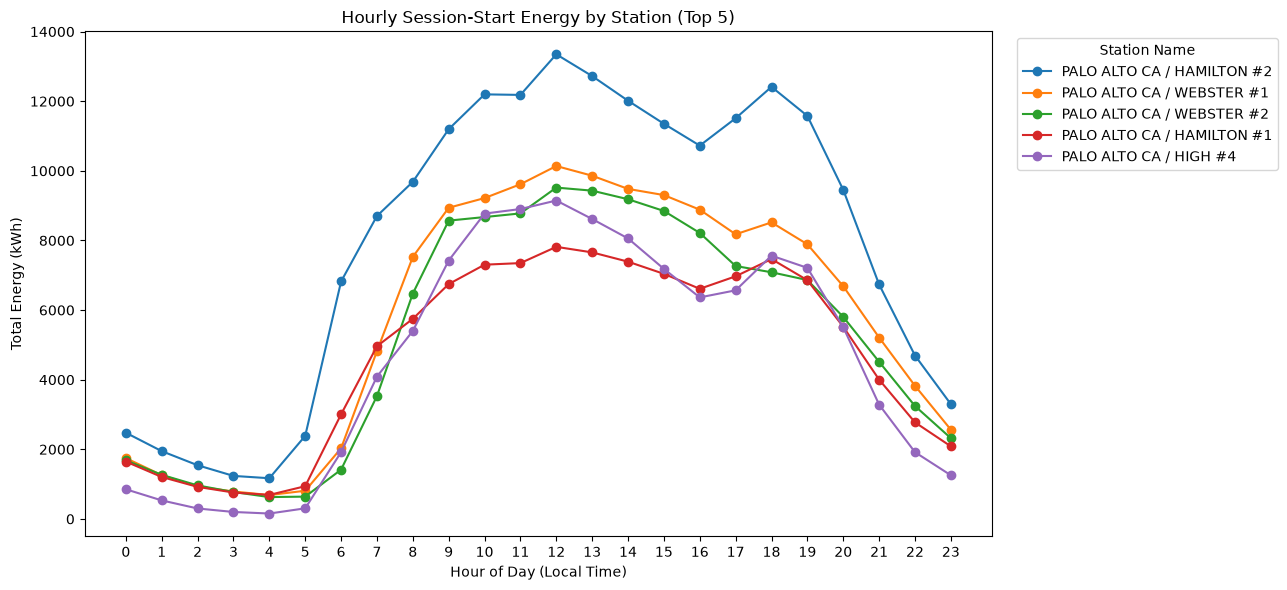

In [19]:
# Select the five stations with the highest total energy
top_5_stations = station_energy.head(5).index

# Extract hour of day
hourly_energy["Hour_Of_Day"] = hourly_energy["Hour"].dt.tz_convert(local_tz).dt.hour

# Calculate energy by station and hour of day
station_hour_pattern = (
    hourly_energy[hourly_energy["Station Name"].isin(top_5_stations)].groupby(["Station Name", "Hour_Of_Day"])["Energy (kWh)"].sum().reset_index())

# Plot each station as a separate line
plt.figure(figsize=(13, 6))
for station in top_5_stations:
    station_data = station_hour_pattern[station_hour_pattern["Station Name"] == station]
    plt.plot( station_data["Hour_Of_Day"],station_data["Energy (kWh)"],marker="o",label=station)

plt.title("Hourly Session-Start Energy by Station (Top 5)")
plt.xlabel("Hour of Day (Local Time)")
plt.ylabel("Total Energy (kWh)")
plt.xticks(range(24))
plt.legend(title="Station Name", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 2.8 Last checks
One final look at column types and missing values in the cleaned data.

In [20]:
print("Dataset shape:", df_time_clean.shape)

column_check = pd.DataFrame({"Column": df_time_clean.columns,"Data_Type": df_time_clean.dtypes.astype(str).values,
    "Non_Null_Count": df_time_clean.notna().sum().values,"Missing_Count": df_time_clean.isna().sum().values,
    "Missing_Percentage": (df_time_clean.isna().mean().values * 100).round(2)})

display(column_check)

Dataset shape: (259072, 41)


,Column,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage
0,Station Name,str,259072,0,0.00
1,MAC Address,str,259072,0,0.00
2,Org Name,str,259072,0,0.00
3,Start Date,datetime64[us],259072,0,0.00
4,Start Time Zone,str,259072,0,0.00
5,End Date,datetime64[us],259072,0,0.00
6,End Time Zone,str,259072,0,0.00
7,Transaction Date (Pacific Time),str,258941,131,0.05
8,Total Duration (hh:mm:ss),str,259072,0,0.00
9,Charging Time (hh:mm:ss),str,259072,0,0.00


692 sessions lasted under two minutes. Plug in, change your mind, leave. They stay in the energy totals because they barely matter there. For the user clustering in Task 1, we'll drop sessions under 0.1 kWh, since those say little about real habits.

In [21]:
# Sessions with exactly 0 minutes
zero_minute = df_time_clean[
    df_time_clean["Elapsed_UTC_Minutes"] == 0
]

# Sessions lasting more than 0 but less than 2 minutes
under_2_minutes = df_time_clean[
    (df_time_clean["Elapsed_UTC_Minutes"] > 0) &
    (df_time_clean["Elapsed_UTC_Minutes"] < 2)
]

# All sessions lasting less than 2 minutes, including zero
less_than_2 = df_time_clean[
    df_time_clean["Elapsed_UTC_Minutes"] < 2
]

print("Zero-minute sessions:", len(zero_minute))
print("Sessions between 0 and 2 minutes:", len(under_2_minutes))
print("Total sessions below 2 minutes:", len(less_than_2))

Zero-minute sessions: 0
Sessions between 0 and 2 minutes: 692
Total sessions below 2 minutes: 692


Sessions per charger, for the sessions that have an `EVSE ID`. The chargers at the top of this list, with 1 to 8 sessions, match the new Sherman stations from Section 2.5.

In [22]:
evse_usage = (
    df_time_clean
    .dropna(subset=["EVSE ID"])
    .groupby("EVSE ID")
    .size()
    .reset_index(name="Total Sessions")
    .sort_values("Total Sessions", ascending=True)
)
display(evse_usage)

,EVSE ID,Total Sessions
41,5526211.0,1
43,5526231.0,1
46,5526281.0,1
48,5526771.0,1
45,5526271.0,1
38,5526171.0,2
44,5526261.0,2
39,5526181.0,3
50,5535441.0,4
42,5526221.0,4
